# Measure image shift in pixels

Estimate horizontal and vertical displacement **from the first image to the second**.

1. Put this notebook and your two images in the same folder, or set their full paths below.
2. Run the cells from top to bottom to measure phase correlation.
3. Inspect the visual check before using a measurement.

This notebook is self-contained; it does not need `measure_shift.py`. Saved outputs show the images configured below. The visual check compares before and after on the same pixels and includes a magnified view.

In [1]:
# Run this line once if the packages are missing (remove the leading #).
# %pip install numpy opencv-python-headless matplotlib

In [1]:
%matplotlib inline
from pathlib import Path
import math
import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

plt.rcParams.update({"figure.dpi": 110, "font.size": 11})

## Choose the images

Phase correlation estimates one translation using the whole frame. Use images where most visible texture moves together. Both images must have the same dimensions.

The supplied `5(1).bmp` → `6(1).bmp` pair has a consistent dominant shift. Appearance changes or motion that differs across the image can make a single translation unreliable; inspect the visual check before using the estimate.


In [2]:
IMAGE1 = Path("images/offset/5.bmp")   # reference / first image
IMAGE2 = Path("images/offset/6.bmp")   # second image


## Measurement functions

The same mild blur is applied to both images to reduce pixel noise. Phase correlation uses a Hann window to reduce boundary artifacts. Measurements always use the original resolution.

In [ ]:
def read_gray(path):
    """Read an 8-bit grayscale image, including paths with Unicode characters."""
    data = np.fromfile(str(path), dtype=np.uint8)
    image = cv2.imdecode(data, cv2.IMREAD_GRAYSCALE)
    if image is None:
        raise ValueError(f"Cannot read image: {path}")
    return image


def calculate_shift(image1, image2):
    """Return (dx, dy, score) for image1 -> image2.

    Inputs: grayscale uint8 NumPy arrays.
    Estimate translation of the complete image using phase correlation.
    The phase response is a diagnostic, not a probability or an accuracy bound.
    """
    if image1.ndim != 2 or image2.ndim != 2:
        raise ValueError("Inputs must be grayscale images.")
    if image1.dtype != np.uint8 or image2.dtype != np.uint8:
        raise ValueError("Inputs must use uint8 pixels.")
    if min(*image1.shape, *image2.shape) < 8:
        raise ValueError("Images must be at least 8 x 8 pixels.")

    # Apply the same mild smoothing to both frames to suppress pixel noise.
    a = cv2.GaussianBlur(image1, (5, 5), 0)
    b = cv2.GaussianBlur(image2, (5, 5), 0)

    if a.shape != b.shape:
        raise ValueError("Phase correlation requires equal image sizes.")
    if min(float(a.std()), float(b.std())) < 1e-3:
        raise ValueError("Images contain too little texture.")
    a = a.astype(np.float32)
    b = b.astype(np.float32)
    a -= a.mean()
    b -= b.mean()
    height, width = a.shape
    # The window reduces artifacts at image boundaries.
    window = cv2.createHanningWindow((width, height), cv2.CV_32F)
    (dx, dy), score = cv2.phaseCorrelate(a, b, window)

    result = (float(dx), float(dy), float(score))
    if not all(math.isfinite(value) for value in result):
        raise ValueError("No finite displacement estimate was found.")
    return result

First image:  5.bmp — 2560 × 1920 pixels
Second image: 6.bmp — 2560 × 1920 pixels


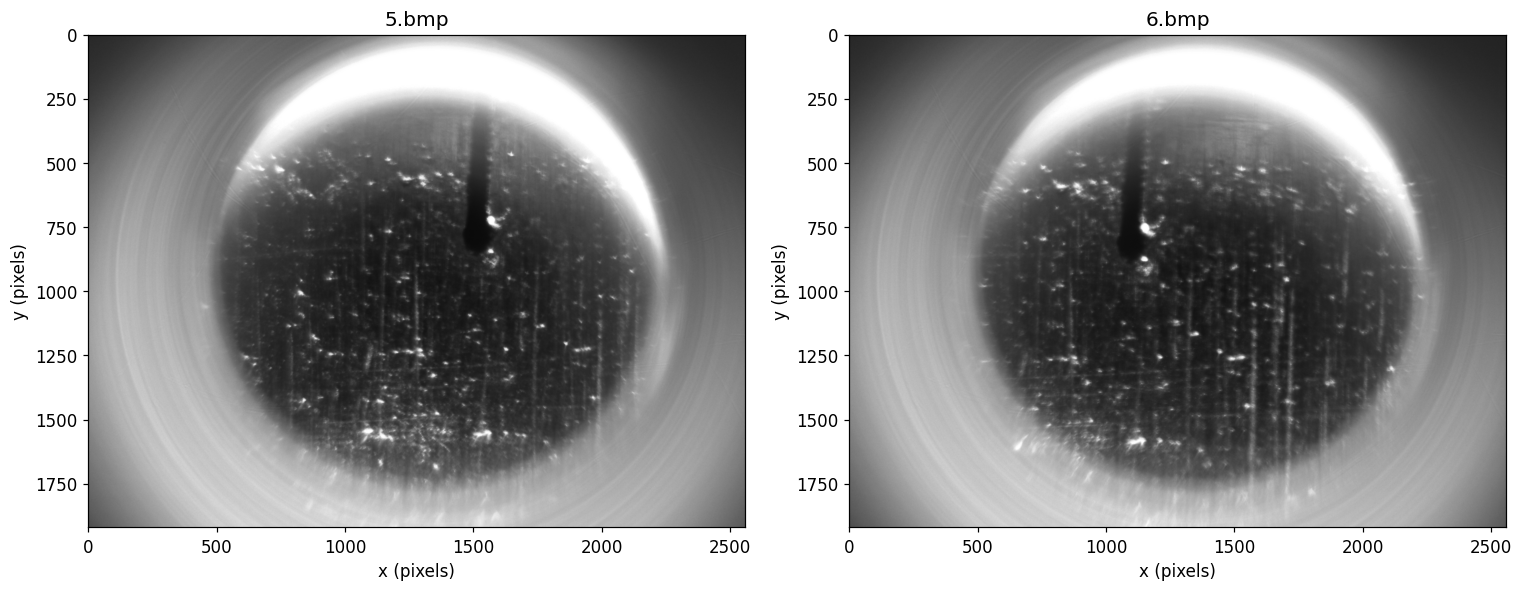

In [4]:
image1 = read_gray(IMAGE1)
image2 = read_gray(IMAGE2)
print(f"First image:  {IMAGE1.name} — {image1.shape[1]} × {image1.shape[0]} pixels")
print(f"Second image: {IMAGE2.name} — {image2.shape[1]} × {image2.shape[0]} pixels")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, image, title in zip(axes, (image1, image2), (IMAGE1.name, IMAGE2.name)):
    # radius = min(image.shape[0], image.shape[1]) // 2 - 100
    # center = (image.shape[1] // 2, image.shape[0] // 2)
    # mask = np.zeros(image.shape[:2], dtype=np.uint8)
    # cv2.circle(mask, center, radius, 255, -1)   

    # image = cv2.bitwise_and(image, image, mask=mask)

    ax.imshow(image, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.set_xlabel("x (pixels)")
    ax.set_ylabel("y (pixels)")
fig.tight_layout()
plt.show()

In [5]:
# x, y, width, height — starting example for your 2560 × 1920 images
PHASE_ROI = (600, 500, 1400, 1100)

x, y, w, h = PHASE_ROI
# use full image for phase correlation
# x, y, w, h = 0, 0, image1.shape[1], image1.shape[0]

# Use identical crop coordinates in both images.
crop1 = image1[y:y+h, x:x+w].copy()
crop2 = image2[y:y+h, x:x+w].copy()

dx, dy, score = calculate_shift(crop1, crop2)

print(f"Exploratory phase crop {PHASE_ROI} (diagnostic only; not applied in the plots):")
print(f"Horizontal shift: {dx:+.2f} px")
print(f"Vertical shift:   {dy:+.2f} px")
print(f"Phase response:   {score:.4f}")

dx, dy, score = calculate_shift(image1, image2)
distance = math.hypot(dx, dy)

print("\nFinal estimate used by the visual check:")
print(f"Direction: {IMAGE1.name} -> {IMAGE2.name}")
print("Method: phase correlation")
print(f"Horizontal shift dx = {dx:+.2f} pixels ({'right' if dx > 0 else 'left' if dx < 0 else 'none'})")
print(f"Vertical shift   dy = {dy:+.2f} pixels ({'down' if dy > 0 else 'up' if dy < 0 else 'none'})")
print(f"Total distance      = {distance:.2f} pixels")
print(f"Match score         = {score:.4f}")
print(f"To align image 2 to image 1, translate by ({-dx:+.2f}, {-dy:+.2f}) pixels.")

# Scores are diagnostics, not probabilities or accuracy bounds.
if score < 0.1:
    print("WARNING: Weak phase response. Inspect corresponding texture and the visual check.")


AttributeError: module 'cv2' has no attribute 'phaseCorrelateIterative'

## Visual check: did the translation help?

All plots use **image 1's pixel coordinates**, with y increasing downward. The estimate describes image 1 → image 2; alignment applies its **negative** to image 2.

- **Red = image 1 (reference); cyan = image 2.** Matching brightness appears gray/white. Colored double edges reveal a remaining offset. Gray areas labeled “no image 2 data” are outside its translated footprint.
- **Before/after difference maps share one color scale.** Darker means closer pixel values. Their mean absolute differences use exactly the same overlapping pixels, excluding interpolation borders. A lower value supports agreement, but reflections, brightness changes, repeated features, and local motion still need visual inspection.
- **The yellow box marks the magnified area.** In the detail view, compare the source images, colored overlay, and alternating checkerboard tiles. A matching edge should continue across tile boundaries. Small labels **1 / 2** identify the first two tile sources.

Set `ZOOM_ROI = (x, y, width, height)` to inspect a specific feature. With `None`, the zoom is near the center of the available overlap. The full frame can disagree even when one local feature matches.


In [6]:
# Change these controls, then rerun the display cell below the helper functions.
ZOOM_ROI = None             # e.g. (1400, 650, 300, 300), in image 1 coordinates
ZOOM_SIZE = (500, 400)      # automatic zoom width / height for phase correlation
CHECKER_TILE = 40           # checkerboard tile size in original pixels
DIFFERENCE_MAX = None      # None: shared 99th percentile; or e.g. 50 (0–255 units)


In [7]:
from matplotlib.patches import Patch


def warp_for_check(moving, reference_shape, shift):
    """Warp into image 1 coordinates; accept only fully supported interpolation."""
    height, width = reference_shape
    transform = np.float32([[1, 0, shift[0]], [0, 1, shift[1]]])
    warped = cv2.warpAffine(moving, transform, (width, height),
                            flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT)
    coverage = cv2.warpAffine(np.ones(moving.shape, dtype=np.float32), transform,
                              (width, height), flags=cv2.INTER_LINEAR,
                              borderMode=cv2.BORDER_CONSTANT)
    return warped, coverage >= 1.0 - 1e-6


def check_overlay(reference, moving, valid):
    """Red reference + cyan moving image; gray marks unavailable moving data."""
    overlay = np.dstack((reference, moving, moving)).astype(np.float32) / 255.0
    overlay[~valid] = (0.35, 0.35, 0.35)
    return overlay


def check_zoom(reference_shape, valid, zoom_roi, zoom_size):
    height, width = reference_shape
    if zoom_roi is None:
        w, h = zoom_size
        if valid.any():
            rows = np.flatnonzero(valid.any(axis=1))
            cols = np.flatnonzero(valid.any(axis=0))
            cx, cy = (cols[0] + cols[-1]) / 2, (rows[0] + rows[-1]) / 2
        else:
            cx, cy = width / 2, height / 2
        zoom_roi = (max(0, round(cx - w / 2)), max(0, round(cy - h / 2)), w, h)
    if (len(zoom_roi) != 4 or any(not isinstance(v, (int, np.integer)) for v in zoom_roi)):
        raise ValueError("ZOOM_ROI must contain four integers: (x, y, width, height).")
    x, y, w, h = zoom_roi
    if x < 0 or y < 0 or x >= width or y >= height or w < 1 or h < 1:
        raise ValueError("ZOOM_ROI must start inside image 1 and have positive dimensions.")
    return x, y, min(w, width - x), min(h, height - y)


def show_alignment_check(reference, moving, dx, dy, *, reference_name, moving_name,
                         zoom_roi=None, zoom_size=(500, 400), tile=40,
                         difference_max=None):
    """Compare one unchanged shift estimate; return diagnostics for shared pixels."""
    if not np.isfinite([dx, dy]).all():
        raise ValueError("The shift must be finite.")
    if not isinstance(tile, (int, np.integer)) or tile < 1:
        raise ValueError("CHECKER_TILE must be a positive integer.")
    if (len(zoom_size) != 2 or any(not isinstance(v, (int, np.integer)) or v < 1
                                   for v in zoom_size)):
        raise ValueError("ZOOM_SIZE must contain two positive integers.")

    original2, before_valid = warp_for_check(moving, reference.shape, (0, 0))
    aligned2, after_valid = warp_for_check(moving, reference.shape, (-dx, -dy))
    # Both errors are evaluated on exactly the same image 1 coordinates.
    shared = before_valid & after_valid
    before_error = np.abs(reference.astype(np.float32) - original2.astype(np.float32))
    after_error = np.abs(reference.astype(np.float32) - aligned2.astype(np.float32))
    before_mae = float(before_error[shared].mean()) if shared.any() else None
    after_mae = float(after_error[shared].mean()) if shared.any() else None
    if difference_max is None:
        errors = np.concatenate((before_error[shared], after_error[shared]))
        difference_max = max(1.0, float(np.percentile(errors, 99))) if errors.size else 255.0
    if not np.isfinite(difference_max) or difference_max <= 0:
        raise ValueError("DIFFERENCE_MAX must be a positive finite number, or None.")

    x, y, w, h = check_zoom(reference.shape, after_valid, zoom_roi, zoom_size)
    detail = np.s_[y:y + h, x:x + w]
    extent = (x - 0.5, x + w - 0.5, y + h - 0.5, y - 0.5)
    overlay_before = check_overlay(reference, original2, before_valid)
    overlay_after = check_overlay(reference, aligned2, after_valid)
    no_data = (0.35, 0.35, 0.35)
    error_cmap = plt.get_cmap("inferno").copy()
    error_cmap.set_bad(no_data)
    gray_cmap = plt.get_cmap("gray").copy()
    gray_cmap.set_bad(no_data)
    mae_label = lambda value: "n/a (no shared pixels)" if value is None else f"{value:.2f} / 255"

    print(f"Reference (red): {reference_name}; image 2 (cyan): {moving_name}")
    print(f"Applied to image 2: x={-dx:+.2f} px, y={-dy:+.2f} px (the inverse estimate).")
    print(f"Image 2 covers {after_valid.mean():.1%} of the reference after alignment.")
    print(f"Mean absolute difference on the same shared pixels ({shared.mean():.1%} of image 1):")
    print(f"  Before: {mae_label(before_mae)}; after: {mae_label(after_mae)}")
    if before_mae is None:
        print("NO SHARED AREA: this shift cannot be checked against the original overlap.")
    elif after_mae > before_mae + 1e-6:
        print("CHECK ALIGNMENT: the translation increased the pixel difference.")
    print(f"Zoom box: (x={x}, y={y}, width={w}, height={h}) in reference coordinates.")

    fig, axes = plt.subplots(2, 2, figsize=(14, 10.5), sharex=True, sharey=True,
                             layout="constrained")
    fig.suptitle(f"Alignment check — reference: {reference_name}; image 2: {moving_name}\n"
                 f"Estimated image 1 → 2: ({dx:+.2f}, {dy:+.2f}) px; "
                 f"applied to image 2: ({-dx:+.2f}, {-dy:+.2f}) px", fontsize=13)
    axes[0, 0].imshow(overlay_before, interpolation="nearest")
    axes[0, 0].set_title("BEFORE — image 2 at its original position")
    axes[0, 1].imshow(overlay_after, interpolation="nearest")
    axes[0, 1].set_title("AFTER — image 2 translated into reference coordinates")
    for ax, error, label, mae in zip(axes[1], (before_error, after_error),
                                    ("BEFORE", "AFTER"), (before_mae, after_mae)):
        heat = ax.imshow(np.ma.array(error, mask=~shared), cmap=error_cmap,
                         vmin=0, vmax=difference_max, interpolation="nearest")
        ax.set_title(f"{label} difference — mean |difference| = {mae_label(mae)}")
    fig.colorbar(heat, ax=list(axes[1]), shrink=0.85, extend="max",
                 label="Absolute brightness difference (0–255); same scale before / after")
    legend = [Patch(facecolor="red", label=f"Reference: {reference_name}"),
              Patch(facecolor="cyan", label=f"Image 2: {moving_name}"),
              Patch(facecolor="white", edgecolor="black", label="Equal brightness"),
              Patch(facecolor=no_data, label="No image 2 data / excluded")]
    axes[0, 0].legend(handles=legend, loc="upper right", fontsize=8, framealpha=0.9)
    for ax in axes.flat:
        ax.add_patch(Rectangle((x - 0.5, y - 0.5), w, h, fill=False,
                                edgecolor="#ffe600", linewidth=1.5))
        ax.set_xlabel("Reference x (pixels)")
        ax.set_ylabel("Reference y (pixels, down)")
    axes[0, 1].text(x, y, " ZOOM", color="#ffe600", fontsize=9, va="bottom",
                    bbox=dict(facecolor="black", alpha=0.7, edgecolor="none", pad=2))
    plt.show()

    # Draw actual cropped arrays so each displayed feature gets enough pixels.
    ref_detail, aligned_detail = reference[detail], aligned2[detail]
    valid_detail = after_valid[detail]
    yy, xx = np.indices((h, w))
    from_reference = (xx // tile + yy // tile) % 2 == 0
    checkerboard = np.where(from_reference, ref_detail, aligned_detail)
    fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharex=True, sharey=True,
                             layout="constrained")
    fig.suptitle(f"Magnified check — reference x={x}…{x + w - 1}, y={y}…{y + h - 1} px\n"
                 "Look for doubled colored edges and jumps across checkerboard seams.", fontsize=13)
    axes[0, 0].imshow(ref_detail, cmap="gray", vmin=0, vmax=255,
                      extent=extent, interpolation="nearest")
    axes[0, 0].set_title(f"1 · Reference — {reference_name}")
    axes[0, 1].imshow(np.ma.array(aligned_detail, mask=~valid_detail), cmap=gray_cmap,
                      vmin=0, vmax=255, extent=extent, interpolation="nearest")
    axes[0, 1].set_title(f"2 · Image 2 AFTER translation — {moving_name}")
    axes[1, 0].imshow(overlay_after[detail], extent=extent, interpolation="nearest")
    axes[1, 0].set_title("AFTER overlay — red reference / cyan image 2")
    axes[1, 1].imshow(np.ma.array(checkerboard, mask=~valid_detail), cmap=gray_cmap,
                      vmin=0, vmax=255, extent=extent, interpolation="nearest")
    axes[1, 1].set_title(f"AFTER checkerboard — alternating {tile} px tiles")
    for col in range(min(2, math.ceil(w / tile))):
        axes[1, 1].text(x + col * tile + min(tile, w - col * tile) / 2 - 0.5,
                        y + min(tile, h) / 2 - 0.5, str(col + 1), ha="center", va="center",
                        color="yellow", fontsize=8,
                        bbox=dict(facecolor="black", alpha=0.6, edgecolor="none", pad=1))
    for ax in axes.flat:
        ax.set_xlabel("Reference x (pixels)")
        ax.set_ylabel("Reference y (pixels, down)")
    plt.show()
    return {"applied_shift": (-dx, -dy), "overlap_fraction": float(after_valid.mean()),
            "shared_fraction": float(shared.mean()), "before_mae": before_mae,
            "after_mae": after_mae, "zoom_roi": (x, y, w, h)}


Reference (red): 5.bmp; image 2 (cyan): 6.bmp
Applied to image 2: x=+416.84 px, y=-30.01 px (the inverse estimate).
Image 2 covers 82.4% of the reference after alignment.
Mean absolute difference on the same shared pixels (82.4% of image 1):
  Before: 9.99 / 255; after: 51.59 / 255
CHECK ALIGNMENT: the translation increased the pixel difference.
Zoom box: (x=1238, y=744, width=500, height=400) in reference coordinates.


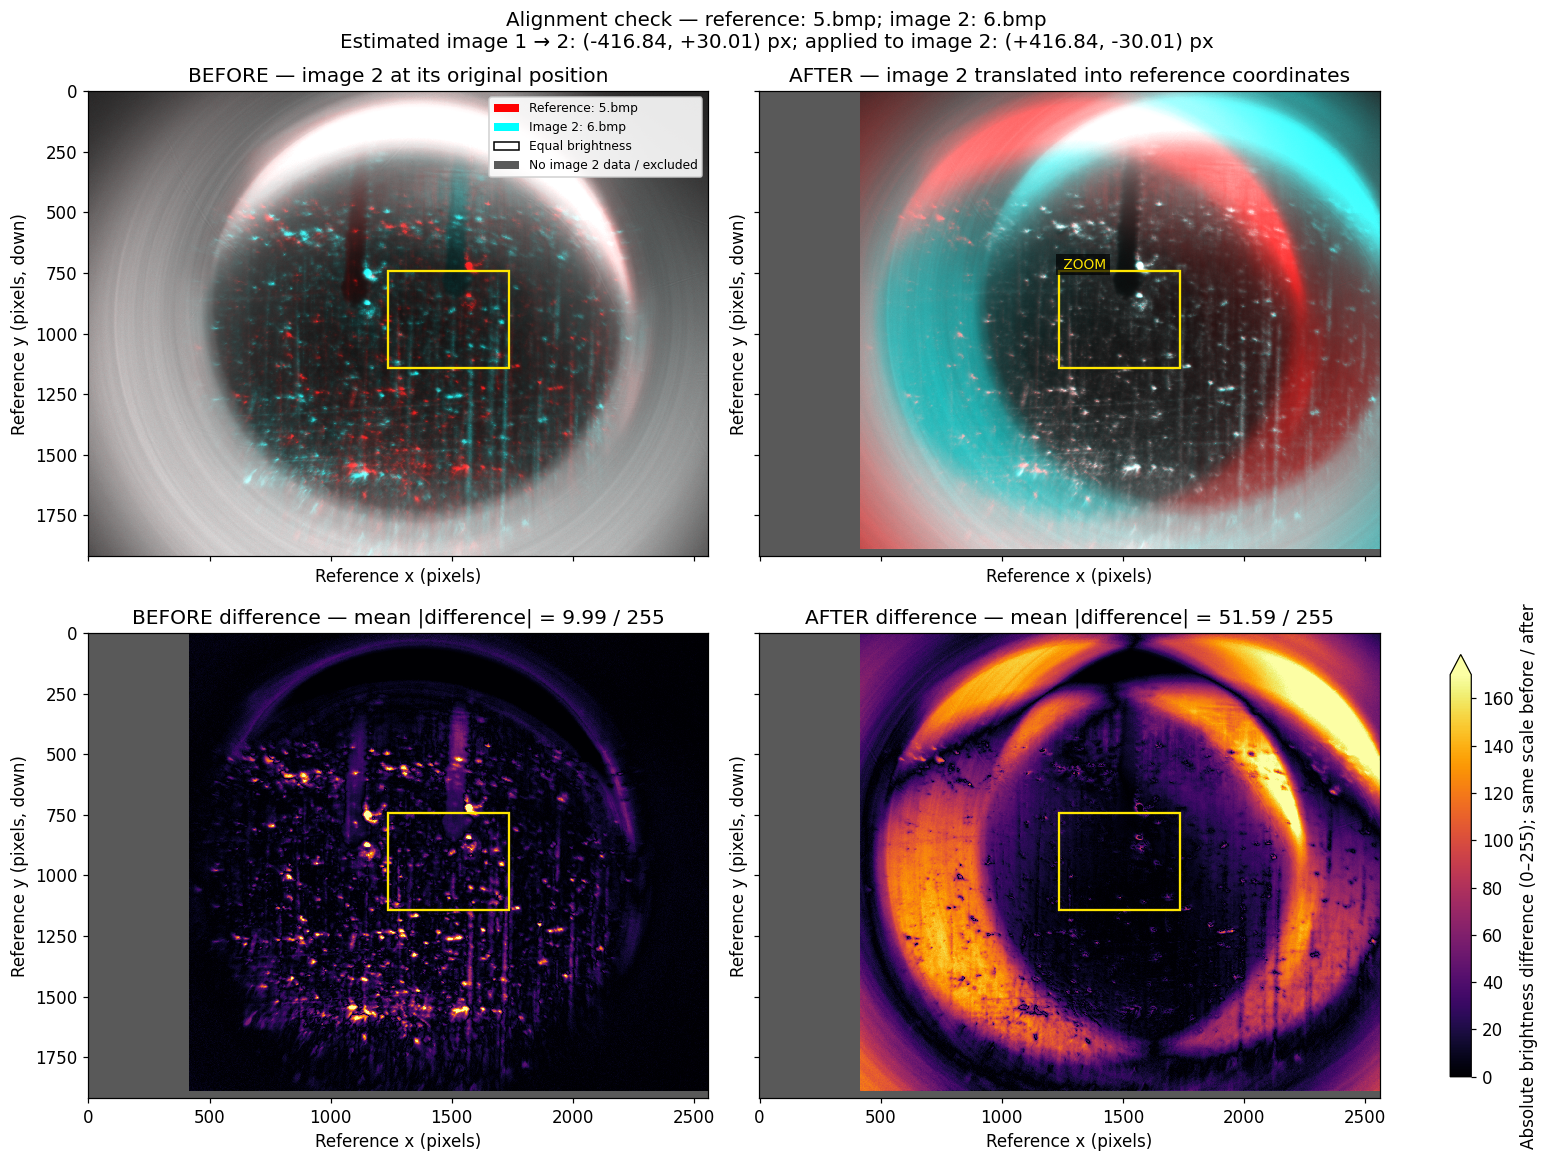

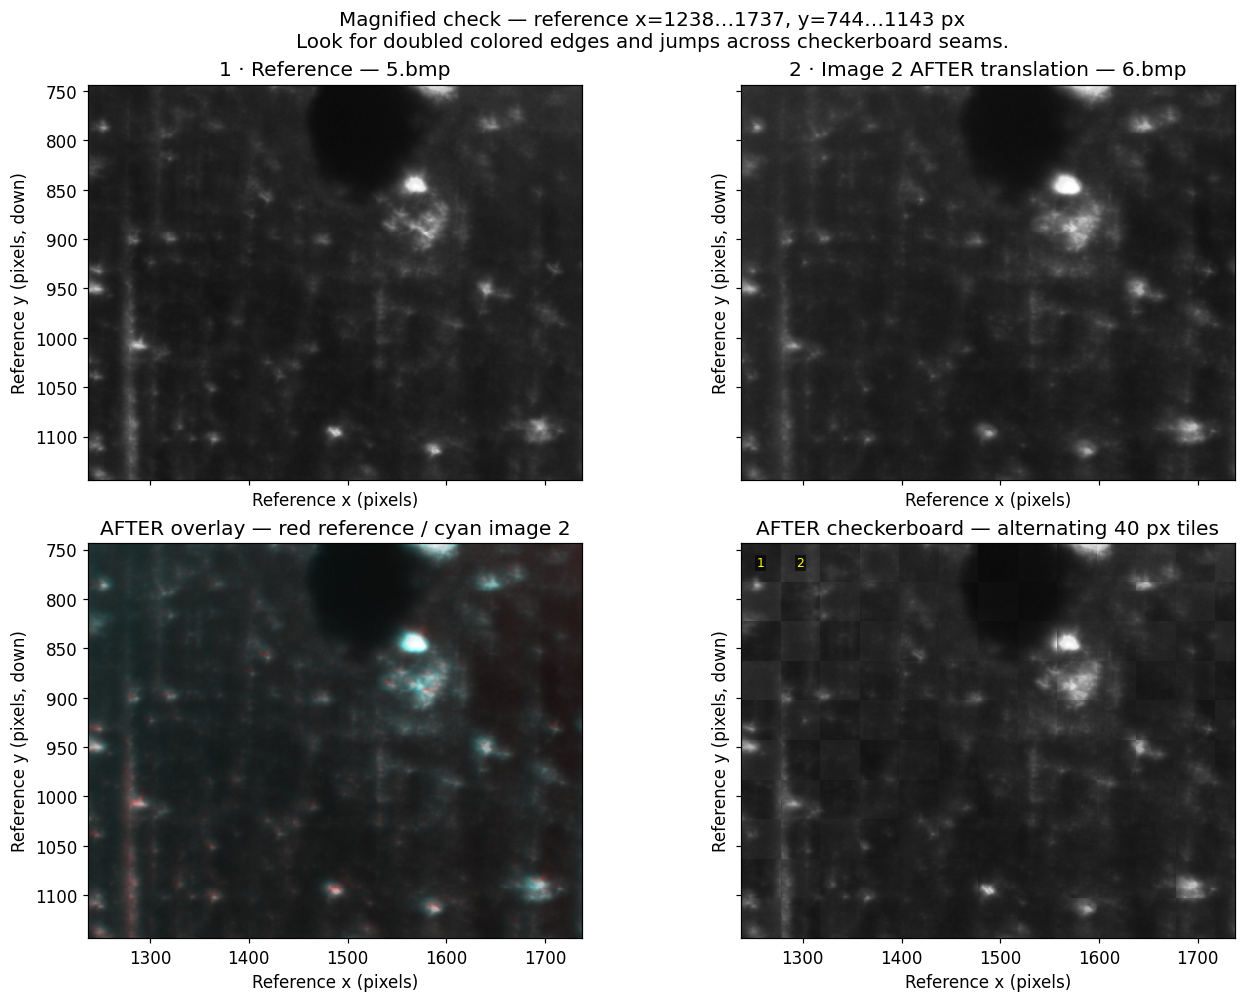

In [8]:
alignment_check = show_alignment_check(
    image1, image2, dx, dy,
    reference_name=IMAGE1.name, moving_name=IMAGE2.name,
    zoom_roi=ZOOM_ROI, zoom_size=ZOOM_SIZE, tile=CHECKER_TILE,
    difference_max=DIFFERENCE_MAX,
)


## Interpreting the result

- Positive `dx` = right; negative `dx` = left.
- Positive `dy` = down; negative `dy` = up.
- `sqrt(dx² + dy²)` is the distance in pixels. A physical distance needs a pixels-per-millimetre calibration.
- Phase correlation reports fractional pixels. Reported decimals do not guarantee subpixel accuracy.
- A high score does not prove a match is correct. Repeated patterns can give ambiguous results. Check the plots and, when needed, compare more than one ROI.
- Phase correlation does not model substantial rotation, scale changes, or deformation. A single translation may not describe every part of the image.

OpenCV references: [phase correlation](https://docs.opencv.org/4.x/d7/df3/group__imgproc__motion.html)